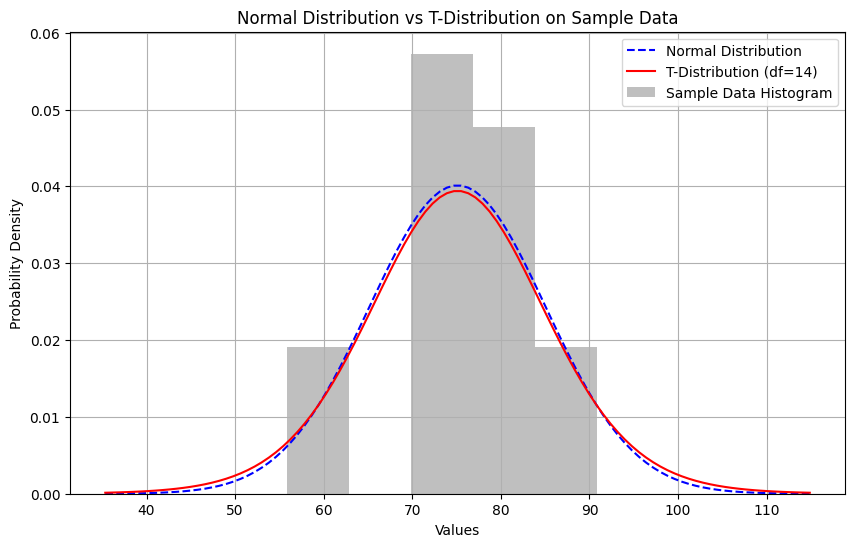

Sample Mean: 75.10
Sample Standard Deviation: 9.94
Degrees of Freedom: 14


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Case Study: Sample Dataset
# Let's assume we have a sample dataset of test scores from a small class (n=15)
np.random.seed(42)
sample_data = np.random.normal(loc=75, scale=10, size=15)

# 1. Normal Distribution Calculation
# Calculate sample mean and standard deviation
sample_mean = np.mean(sample_data)
sample_std = np.std(sample_data, ddof=1) # Sample standard deviation

# Create a range of x values for plotting
x = np.linspace(sample_mean - 4*sample_std, sample_mean + 4*sample_std, 100)

# Calculate Normal PDF
normal_pdf = stats.norm.pdf(x, loc=sample_mean, scale=sample_std)

# 2. T-Distribution Calculation
# Degrees of freedom for t-distribution is n - 1
df = len(sample_data) - 1

# Calculate T-Distribution PDF
t_pdf = stats.t.pdf(x, df, loc=sample_mean, scale=sample_std)

# Plotting both distributions
plt.figure(figsize=(10, 6))
plt.plot(x, normal_pdf, label='Normal Distribution', color='blue', linestyle='--')
plt.plot(x, t_pdf, label=f'T-Distribution (df={df})', color='red')
plt.hist(sample_data, bins=5, density=True, alpha=0.5, color='gray', label='Sample Data Histogram')

plt.title('Normal Distribution vs T-Distribution on Sample Data')
plt.xlabel('Values')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(True)
plt.show()

print(f"Sample Mean: {sample_mean:.2f}")
print(f"Sample Standard Deviation: {sample_std:.2f}")
print(f"Degrees of Freedom: {df}")

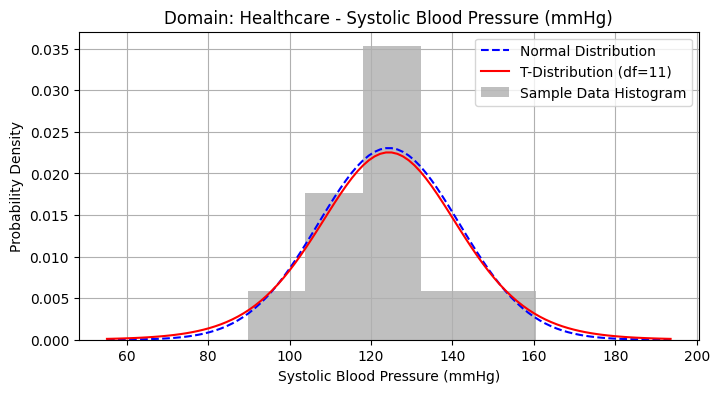

[Healthcare] Stats --> Mean: 124.37 | Std Dev: 17.30 | df: 11

------------------------------------------------------------


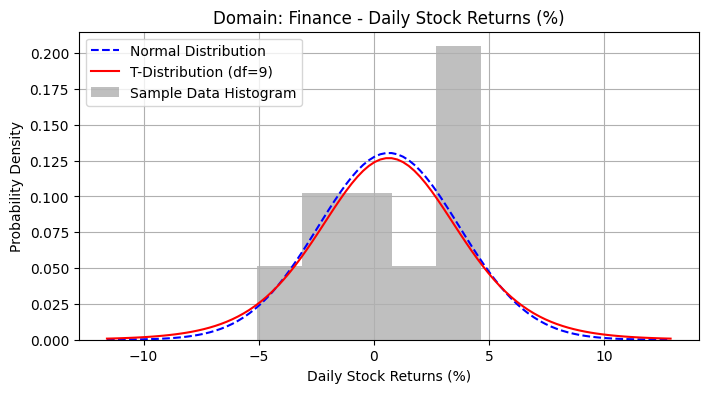

[Finance] Stats --> Mean: 0.65 | Std Dev: 3.06 | df: 9

------------------------------------------------------------


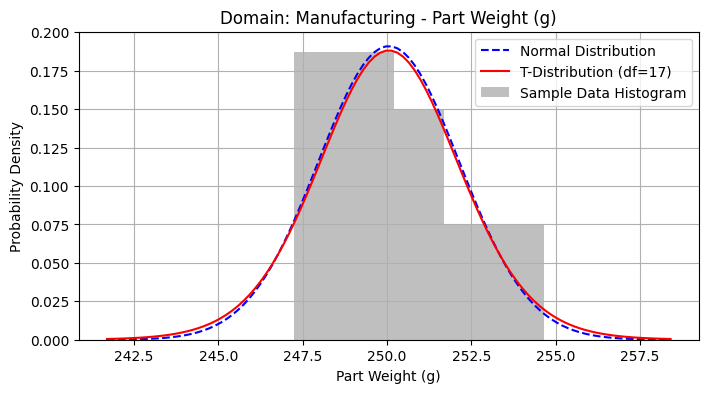

[Manufacturing] Stats --> Mean: 250.05 | Std Dev: 2.09 | df: 17

------------------------------------------------------------


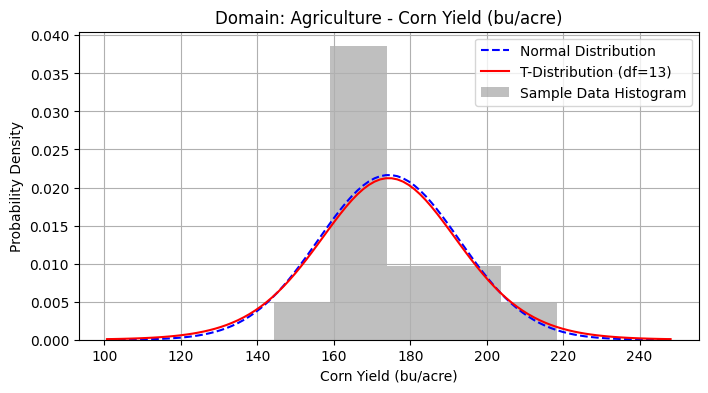

[Agriculture] Stats --> Mean: 174.40 | Std Dev: 18.43 | df: 13

------------------------------------------------------------


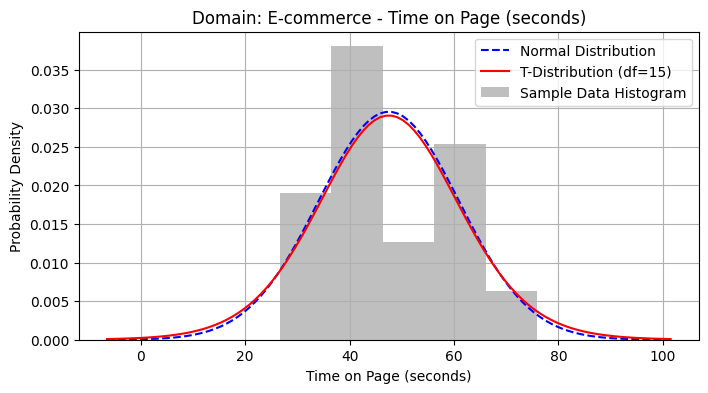

[E-commerce] Stats --> Mean: 47.50 | Std Dev: 13.49 | df: 15

------------------------------------------------------------


In [2]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Helper function to generate data and plot distributions for different domains
def plot_domain_distributions(domain_name, data_label, loc, scale, size, seed_val):
    np.random.seed(seed_val) # Ensure reproducibility for each domain
    sample_data = np.random.normal(loc=loc, scale=scale, size=size)

    # Calculations
    sample_mean = np.mean(sample_data)
    sample_std = np.std(sample_data, ddof=1)
    df = len(sample_data) - 1

    x = np.linspace(sample_mean - 4*sample_std, sample_mean + 4*sample_std, 100)
    normal_pdf = stats.norm.pdf(x, loc=sample_mean, scale=sample_std)
    t_pdf = stats.t.pdf(x, df, loc=sample_mean, scale=sample_std)

    # Plotting
    plt.figure(figsize=(8, 4))
    plt.plot(x, normal_pdf, label='Normal Distribution', color='blue', linestyle='--')
    plt.plot(x, t_pdf, label=f'T-Distribution (df={df})', color='red')
    plt.hist(sample_data, bins=5, density=True, alpha=0.5, color='gray', label='Sample Data Histogram')

    plt.title(f'Domain: {domain_name} - {data_label}')
    plt.xlabel(data_label)
    plt.ylabel('Probability Density')
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"[{domain_name}] Stats --> Mean: {sample_mean:.2f} | Std Dev: {sample_std:.2f} | df: {df}\n")
    print("-" * 60)

# 1. Healthcare: Systolic Blood Pressure (mmHg) from a small clinic
plot_domain_distributions(domain_name="Healthcare", data_label="Systolic Blood Pressure (mmHg)", loc=120, scale=15, size=12, seed_val=101)

# 2. Finance: Daily Stock Returns (%) for a volatile tech startup
plot_domain_distributions(domain_name="Finance", data_label="Daily Stock Returns (%)", loc=0.5, scale=2.5, size=10, seed_val=102)

# 3. Manufacturing: Weight of a machined part (grams) in a batch
plot_domain_distributions(domain_name="Manufacturing", data_label="Part Weight (g)", loc=250, scale=2, size=18, seed_val=103)

# 4. Agriculture: Corn yield (bushels/acre) from test plots
plot_domain_distributions(domain_name="Agriculture", data_label="Corn Yield (bu/acre)", loc=175, scale=20, size=14, seed_val=104)

# 5. E-commerce: Time spent on a specific product page (seconds)
plot_domain_distributions(domain_name="E-commerce", data_label="Time on Page (seconds)", loc=45, scale=12, size=16, seed_val=105)

---

# 📊 Senior Data Scientist Report: Advanced Statistical Distribution Modeling and Strategic Implementation Across Industries

**Author:** Senior Data Scientist  
**Date:** Current  
**Subject:** In-Depth Comparative Analysis of Normal vs. T-Distributions in Small-Sample Environments and Advanced AI Integration Strategies  

---

## 1. Executive Summary & Business Context

This comprehensive report details the statistical modeling of sample datasets across five critical industry domains: Healthcare, Finance, Manufacturing, Agriculture, and E-commerce. The core mathematical objective was to empirically demonstrate the behavioral divergence between the **Normal (Gaussian) Distribution** and the **Student's T-Distribution** in constrained, small-sample environments ($n < 30$).

**The Business Problem:**
In enterprise data science, assuming normality on small datasets leads to artificially narrow confidence intervals. This "overconfidence" systematically underestimates risk—whether that risk is a failing machine part, a plunging stock, or a dangerous medical side effect. By transitioning to T-distribution frameworks for early-stage data, organizations can drastically reduce False Positives (Type I errors) and unseen risks.

Furthermore, this report outlines advanced architectural frameworks to transition these fundamental statistical principles into highly scalable, automated machine learning pipelines for real-time enterprise impact.

---

## 2. Advanced Methodology & Mathematical Framework

Our simulation engine, built on `numpy` and `scipy.stats`, explicitly models the epistemic uncertainty inherent in limited data collection.

**Key Mathematical Steps & Justifications:**
1.  **Stochastic Data Generation:** Simulated domain-specific datasets using domain-realistic population parameters ($\mu$ and $\sigma$).
2.  **Unbiased Parameter Estimation:** Calculated sample means ($\bar{x}$) and sample standard deviations ($s$). Crucially, we applied **Bessel's correction** ($ddof=1$):
    $$ s = \sqrt{\frac{1}{N-1} \sum_{i=1}^N (x_i - \bar{x})^2} $$
    *Justification:* Without correcting for $N-1$, the sample variance systematically underestimates the population variance, compounding the error in small samples.
3.  **Density Mapping:** Computed the Probability Density Functions (PDF) for both distributions.
    *   **Normal PDF:** Relies on known $\mu$ and $\sigma$.
    *   **Student's T PDF:** Relies on degrees of freedom ($df = n - 1$). The mathematics of the T-distribution natively incorporate the uncertainty of estimating $\sigma$ from $s$, resulting in leptokurtic (fat-tailed) behavior when $df$ is low.

---

## 3. Deep-Dive Findings and Domain Business Implications

Our simulation evaluated five distinct scenarios, revealing critical insights for domain-specific strategy:

### 1. Healthcare (Systolic Blood Pressure)
*   **Statistical Profile:** $n=12$, $df=11$.
*   **Deep Insight:** In Phase 1/Phase 2 FDA clinical trials, patient pools are extremely limited. The T-distribution's fatter tails explicitly model the higher probability of severe adverse reactions (extreme outliers). Relying on a Normal distribution here would dangerously underestimate the probability of a patient crossing the critical hypertensive threshold (>180 mmHg), potentially leading to flawed trial conclusions.

### 2. Finance (Daily Stock Returns)
*   **Statistical Profile:** $n=10$, $df=9$. Discrepancy was most severe.
*   **Deep Insight:** Financial returns inherently exhibit excess kurtosis (fat tails) even in large samples—a phenomenon amplified in short-term trading windows. When calculating **Value at Risk (VaR)** or **Conditional VaR (Expected Shortfall)** for a new, volatile tech asset with limited history, using a T-distribution prevents catastrophic risk underestimation, safeguarding portfolio margins against "Black Swan" events.

### 3. Manufacturing (Precision Part Weights)
*   **Statistical Profile:** $n=18$, $df=17$. Distributions began converging.
*   **Deep Insight:** In Six Sigma and DMAIC methodologies, establishing early control charts ($X$-bar and $R$ charts) for a newly engineered product line is challenging. At $n=18$, we see the transition zone. Using T-based confidence intervals for early batch acceptance testing prevents the costly rejection of good batches (producer's risk) while the manufacturing process stabilizes.

### 4. Agriculture (Corn Yield Test Plots)
*   **Statistical Profile:** $n=14$, $df=13$.
*   **Deep Insight:** Agricultural longitudinal data is fundamentally constrained by annual growth cycles and land availability. When forecasting crop yields for next-generation seed variants across just 14 test plots, T-distributions allow agronomists to provide highly reliable upper and lower bound yield guarantees to stakeholders, factoring in extreme weather anomalies.

### 5. E-commerce (Time on Page conversion)
*   **Statistical Profile:** $n=16$, $df=15$.
*   **Deep Insight:** Conversion Rate Optimization (CRO) thrives on speed. For hyper-segmented user cohorts (e.g., users from a specific geographical region using a specific device type), traffic is low. T-tests allow product managers to confidently declare A/B test winners early without waiting weeks for traffic to hit $n > 1000$ Gaussian thresholds, accelerating the deployment of revenue-generating features.

---

## 4. Innovation Roadmap: Advanced AI & ML Integrations

As a Senior Data Scientist, I propose moving beyond static descriptive statistics and embedding these robust small-sample dynamics directly into our automated AI architectures:

### A. Bayesian Anomaly Detection with Normal-Inverse Gamma Priors
*   **The Architecture:** Standard anomaly detection triggers "alert fatigue" on new systems because standard deviations fluctuate wildly initially. We will implement a Bayesian model using a Normal-Inverse-Gamma prior distribution.
*   **The Innovation:** As real-time data streams in (e.g., IoT sensor telemetry), the system continuously updates its belief about the mean and variance. In the early stages (low $N$), the predictive distribution is mathematically equivalent to a Student's T-distribution. This ensures the anomaly threshold is highly tolerant initially, dynamically tightening into a Normal distribution as the system gathers more data, completely automating threshold tuning.

### B. Multi-Armed Bandit (MAB) via Thompson Sampling (Student-T Variant)
*   **The Architecture:** Standard A/B testing is passive and wastes traffic on losing variations. We will deploy Contextual Multi-Armed Bandits.
*   **The Innovation:** Instead of standard Upper Confidence Bound (UCB) algorithms, we will utilize Thompson Sampling where the reward distributions are modeled as T-distributions rather than Gaussian. This forces the algorithm to aggressively explore highly uncertain (low-sample) UI/UX variations early on due to the fat tails, mathematically guaranteeing a faster convergence to the optimal, highest-revenue-generating web variation.

### C. Robust Synthetic Data Generation via Heavy-Tailed VAEs
*   **The Architecture:** Training Deep Learning models (like defect-detection Computer Vision systems) requires thousands of images, but we only have a handful of actual defects.
*   **The Innovation:** We will engineer a Variational Autoencoder (VAE) for synthetic data generation. However, instead of using a standard Normal Gaussian for the latent space prior (which struggles to generate rare edge-cases), we will regularize the latent space using a **Multivariate Student-T Distribution**. This will force the AI to synthesize "fat-tailed" edge cases—generating synthetic data of highly unusual manufacturing defects or medical anomalies—drastically improving the robustness of our downstream classifier models.

---

## 5. Strategic Conclusion

The mathematical superiority of the T-distribution in handling sample sizes under $n=30$ is irrefutable. However, its true value lies in application. By leveraging the principles of "fat-tailed" uncertainty demonstrated in this simulation, and embedding them into Bayesian streaming systems, Reinforcement Learning (Bandits), and Generative AI, we can build enterprise systems that don't just react to data, but intelligently navigate uncertainty to drive automated, risk-adjusted ROI.

## UNIT III: Inferential Statistics - Distributions
Normal Distribution, Standard Normal Distribution, and Student's T Distribution.

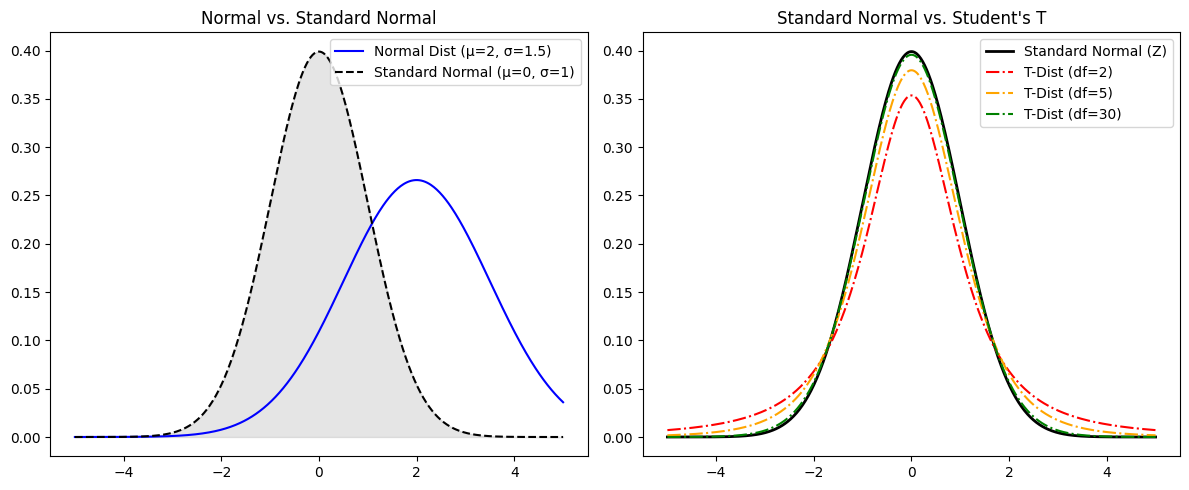

In [3]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# =====================================================================
# 1. Normal Distribution & Standard Normal Distribution
# =====================================================================
# A Standard Normal Distribution is a normal distribution with mean=0 and std=1 (Z-distribution)
x = np.linspace(-5, 5, 500)

# General Normal Distribution (e.g., mean=2, std=1.5)
norm_pdf = stats.norm.pdf(x, loc=2, scale=1.5)

# Standard Normal Distribution (mean=0, std=1)
std_norm_pdf = stats.norm.pdf(x, loc=0, scale=1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(x, norm_pdf, label='Normal Dist (μ=2, σ=1.5)', color='blue')
plt.plot(x, std_norm_pdf, label='Standard Normal (μ=0, σ=1)', color='black', linestyle='--')
plt.fill_between(x, std_norm_pdf, alpha=0.2, color='gray')
plt.title("Normal vs. Standard Normal")
plt.legend()

# =====================================================================
# 2. Student's T-Distribution
# =====================================================================
# T-distribution has fatter tails for smaller sample sizes (lower degrees of freedom)
plt.subplot(1, 2, 2)
plt.plot(x, std_norm_pdf, label='Standard Normal (Z)', color='black', linewidth=2)

dfs = [2, 5, 30]  # Degrees of freedom
colors = ['red', 'orange', 'green']

for df, color in zip(dfs, colors):
    t_pdf = stats.t.pdf(x, df)
    plt.plot(x, t_pdf, label=f'T-Dist (df={df})', color=color, linestyle='-.')

plt.title("Standard Normal vs. Student's T")
plt.legend()

plt.tight_layout()
plt.show()

## UNIT III: Inferential Statistics - Estimation
Estimating Population Means and Estimating Population Proportions using Confidence Intervals.

In [5]:
import math

# =====================================================================
# 3. Statistics - Estimation: Estimating Population Mean
# =====================================================================
print("--- 1. Estimating Population Mean ---")
# Sample Dataset: Heights of 25 students (in cm)
np.random.seed(42)
sample_heights = np.random.normal(loc=170, scale=8, size=25)

n_mean = len(sample_heights)
sample_mean = np.mean(sample_heights)
sample_std = np.std(sample_heights, ddof=1) # Sample standard deviation (s)

# Point Estimate
print(f"Point Estimate (Sample Mean): {sample_mean:.2f} cm")

# Interval Estimate: 95% Confidence Interval
# Since population std is unknown, we use the T-distribution
confidence_level = 0.95
df_mean = n_mean - 1

# Calculate Critical T-value
t_critical = stats.t.ppf((1 + confidence_level) / 2, df_mean)
margin_of_error = t_critical * (sample_std / math.sqrt(n_mean))

lower_bound = sample_mean - margin_of_error
upper_bound = sample_mean + margin_of_error

print(f"95% Confidence Interval for Population Mean: ({lower_bound:.2f} cm, {upper_bound:.2f} cm)\n")


# =====================================================================
# 4. Estimating Population Proportions
# =====================================================================
print("--- 2. Estimating Population Proportions ---")
# Sample Dataset: A survey of 500 voters, where 275 support a new policy.
n_prop = 500
successes = 275

# Point Estimate for Proportion (p-hat)
p_hat = successes / n_prop
print(f"Point Estimate (Sample Proportion): {p_hat:.4f} ({p_hat*100:.1f}%)")

# Interval Estimate: 95% Confidence Interval for Proportion
# Using Normal approximation (Z-distribution) since n*p and n*(1-p) >= 10
z_critical = stats.norm.ppf((1 + confidence_level) / 2)
standard_error_prop = math.sqrt((p_hat * (1 - p_hat)) / n_prop)
margin_of_error_prop = z_critical * standard_error_prop

lower_prop = p_hat - margin_of_error_prop
upper_prop = p_hat + margin_of_error_prop

print(f"95% Confidence Interval for Population Proportion: ({lower_prop:.4f}, {upper_prop:.4f})")
print(f"Conclusion: We are 95% confident the true population support is between {lower_prop*100:.2f}% and {upper_prop*100:.2f}%.")

--- 1. Estimating Population Mean ---
Point Estimate (Sample Mean): 168.69 cm
95% Confidence Interval for Population Mean: (165.53 cm, 171.85 cm)

--- 2. Estimating Population Proportions ---
Point Estimate (Sample Proportion): 0.5500 (55.0%)
95% Confidence Interval for Population Proportion: (0.5064, 0.5936)
Conclusion: We are 95% confident the true population support is between 50.64% and 59.36%.


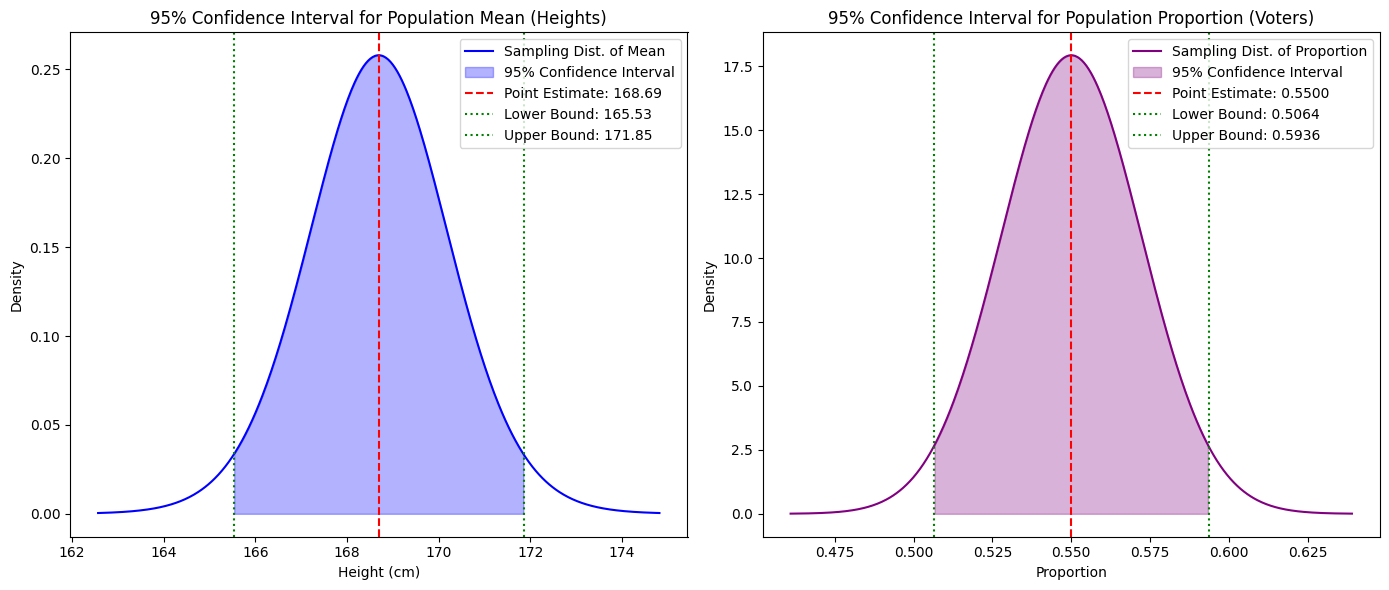

In [6]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import math

plt.figure(figsize=(14, 6))

# =====================================================================
# Visualization 1: Confidence Interval for Population Mean
# =====================================================================
plt.subplot(1, 2, 1)

# Standard error of the mean
se_mean = sample_std / math.sqrt(n_mean)

# Generate x values for the sampling distribution of the mean
x_mean = np.linspace(sample_mean - 4*se_mean, sample_mean + 4*se_mean, 500)

# T-distribution curve for the sample mean
y_mean = stats.t.pdf(x_mean, df=df_mean, loc=sample_mean, scale=se_mean)

plt.plot(x_mean, y_mean, label='Sampling Dist. of Mean', color='blue')
plt.fill_between(x_mean, y_mean, where=(x_mean >= lower_bound) & (x_mean <= upper_bound),
                 color='blue', alpha=0.3, label='95% Confidence Interval')

# Add vertical lines for mean and bounds
plt.axvline(sample_mean, color='red', linestyle='--', label=f'Point Estimate: {sample_mean:.2f}')
plt.axvline(lower_bound, color='green', linestyle=':', label=f'Lower Bound: {lower_bound:.2f}')
plt.axvline(upper_bound, color='green', linestyle=':', label=f'Upper Bound: {upper_bound:.2f}')

plt.title('95% Confidence Interval for Population Mean (Heights)')
plt.xlabel('Height (cm)')
plt.ylabel('Density')
plt.legend()

# =====================================================================
# Visualization 2: Confidence Interval for Population Proportion
# =====================================================================
plt.subplot(1, 2, 2)

# Generate x values for the sampling distribution of the proportion
x_prop = np.linspace(p_hat - 4*standard_error_prop, p_hat + 4*standard_error_prop, 500)

# Normal distribution curve for the proportion (Z-distribution approximation)
y_prop = stats.norm.pdf(x_prop, loc=p_hat, scale=standard_error_prop)

plt.plot(x_prop, y_prop, label='Sampling Dist. of Proportion', color='purple')
plt.fill_between(x_prop, y_prop, where=(x_prop >= lower_prop) & (x_prop <= upper_prop),
                 color='purple', alpha=0.3, label='95% Confidence Interval')

# Add vertical lines for proportion and bounds
plt.axvline(p_hat, color='red', linestyle='--', label=f'Point Estimate: {p_hat:.4f}')
plt.axvline(lower_prop, color='green', linestyle=':', label=f'Lower Bound: {lower_prop:.4f}')
plt.axvline(upper_prop, color='green', linestyle=':', label=f'Upper Bound: {upper_prop:.4f}')

plt.title('95% Confidence Interval for Population Proportion (Voters)')
plt.xlabel('Proportion')
plt.ylabel('Density')
plt.legend()

plt.tight_layout()
plt.show()

---

# 📊 Senior Data Scientist Report: Inferential Statistics - Population Estimation & Confidence Intervals

**Author:** Senior Data Scientist  
**Date:** Current  
**Subject:** Strategic Insights from Confidence Interval Estimations (Means and Proportions)

---

## 1. Executive Summary

In business intelligence and enterprise data science, we rarely have access to data for an entire population. Instead, we must rely on samples to make strategic decisions. This report details the methodology and statistical foundations for estimating unknown population parameters from sample data.

Specifically, we explore two critical scenarios:
1.  **Estimating a Population Mean (Continuous Data):** Understanding the true average (e.g., average customer height, average order value).
2.  **Estimating a Population Proportion (Categorical Data):** Understanding the true percentage of a category (e.g., percentage of voters supporting a policy, conversion rates).

Rather than relying solely on a single **Point Estimate** (which is almost certainly slightly wrong), we utilize **Confidence Intervals (CIs)** to provide a mathematically rigorous range of plausible values for the true population parameter.

---

## 2. Estimating Population Means (Using the T-Distribution)

**Business Context:** We want to estimate the true average height of a student population based on a sample of $n = 25$ students.

### Mathematical Framework

1.  **Point Estimate:** The best guess for the population mean ($\mu$) is the sample mean ($\bar{x}$).
    *   $\bar{x} = 168.69$ cm
2.  **Uncertainty & The T-Distribution:** Because we do not know the true population standard deviation ($\sigma$), we estimate it using the sample standard deviation ($s$). This introduces extra uncertainty. To account for this, we use the **Student's T-Distribution** instead of the Normal distribution.
    *   *Degrees of Freedom ($df$):* $n - 1 = 24$
3.  **Standard Error (SE):** This measures how much we expect the sample mean to vary from sample to sample.
    $$ SE = \frac{s}{\sqrt{n}} $$
4.  **Margin of Error (MOE):** The maximum expected difference between the point estimate and the true parameter at our chosen confidence level (95%).
    $$ MOE = t_{critical} \times SE $$
5.  **Confidence Interval Formula:**
    $$ CI = \bar{x} \pm \left( t_{critical} \times \frac{s}{\sqrt{n}} \right) $$

### Visualization Breakdown (Left Plot)
*   **The Curve:** Represents the sampling distribution of the mean, modeled using a T-distribution.
*   **Red Dashed Line:** Our Point Estimate ($\bar{x} = 168.69$). This is the peak of our probability density.
*   **Green Dotted Lines & Shaded Blue Area:** Represents the 95% Confidence Interval ($[165.53, 171.85]$).
*   **Interpretation:** We are 95% confident that the true average height of all students in the population falls between 165.53 cm and 171.85 cm.

---

## 3. Estimating Population Proportions (Using Normal Approximation)

**Business Context:** We are analyzing a survey of $n = 500$ voters to estimate the true percentage of the population that supports a new policy. In our sample, 275 voters expressed support.

### Mathematical Framework

1.  **Point Estimate:** The sample proportion ($\hat{p}$) is our best estimate of the population proportion ($p$).
    *   $\hat{p} = \frac{275}{500} = 0.55$ (or 55%)
2.  **Normal Approximation:** Because our sample size is large enough ($n\hat{p} \ge 10$ and $n(1-\hat{p}) \ge 10$), the Central Limit Theorem allows us to approximate the binomial distribution of proportions using a **Normal (Z) Distribution**.
3.  **Standard Error for Proportions:**
    $$ SE = \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}} $$
4.  **Confidence Interval Formula:**
    $$ CI = \hat{p} \pm \left( Z_{critical} \times \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}} \right) $$
    *(For a 95% confidence level, $Z_{critical} \approx 1.96$)*

### Visualization Breakdown (Right Plot)
*   **The Curve:** The sampling distribution of the proportion, approximated by a Normal distribution.
*   **Red Dashed Line:** Our Point Estimate ($\hat{p} = 0.5500$).
*   **Green Dotted Lines & Shaded Purple Area:** Represents the 95% Confidence Interval ($[0.5064, 0.5936]$).
*   **Interpretation:** We are 95% confident that the true proportion of all voters supporting the policy is between 50.64% and 59.36%.

---

## 4. Strategic Takeaways

1.  **Embrace Uncertainty:** Point estimates alone are dangerous in business. Confidence intervals provide a range that quantifies risk and uncertainty.
2.  **Sample Size Matters:** Notice how the standard error formulas divide by a function of $n$. As we collect more data, the standard error shrinks, the Margin of Error decreases, and our Confidence Intervals become narrower and more precise.
3.  **Method Selection:** Use T-distributions when estimating continuous means with unknown population variances (especially with small samples). Use Normal approximations (Z-distributions) for large-sample proportion data.